<a href="https://colab.research.google.com/github/laksamanaap/PCVK_Ganjil_2026/blob/main/P7/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from google.colab.patches import cv2_imshow
from skimage import data, filters, segmentation, color
from skimage.segmentation import flood
from sklearn.cluster import KMeans
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


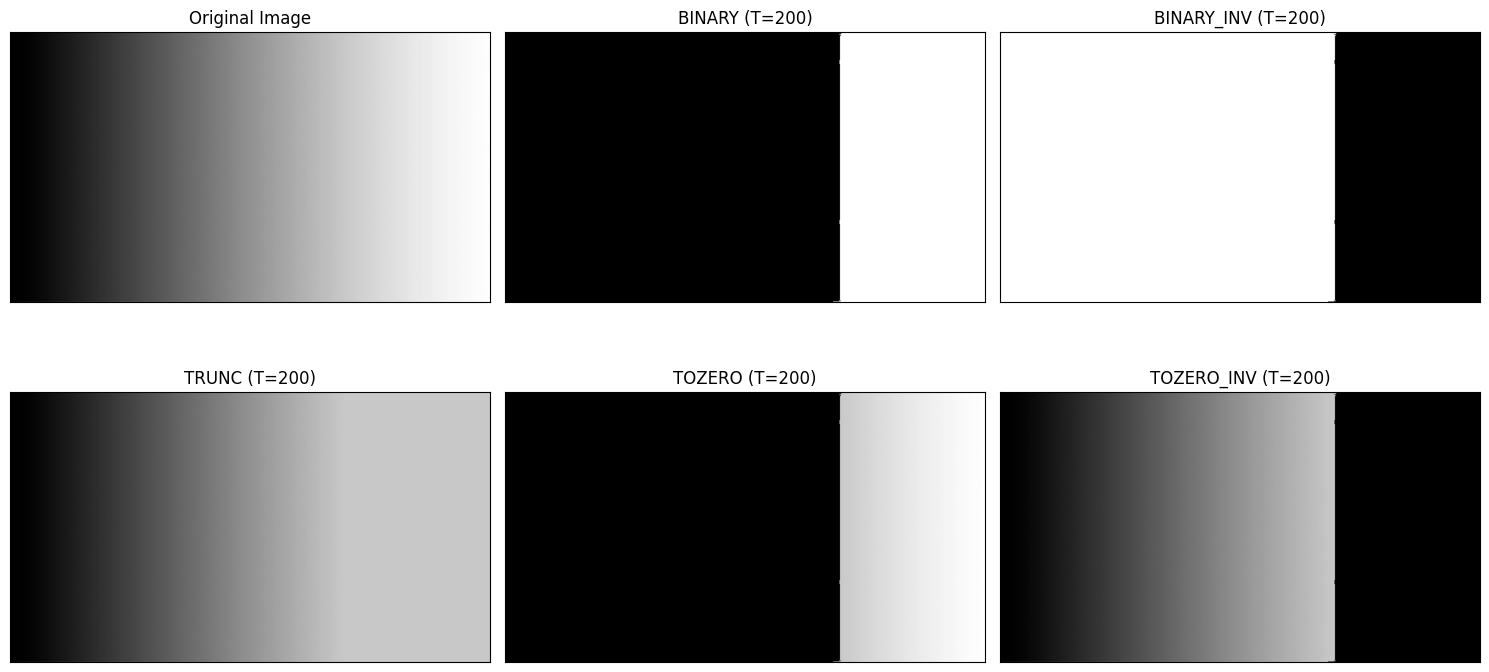

In [ ]:
### Global threshold manual

filename = '/content/drive/MyDrive/PCVK_img/gradient.jpg'

img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        f"Gambar tidak ditemukan: {filename}"
    )

thresh = 200
maxval = 255

# 1. Binary
binary = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. Binary Inverse
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. Truncate
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. To Zero
tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. To Zero Inverse
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# Tampilkan hasil
images = [
    img, binary, binary_inv,
    trunc, tozero, tozero_inv
]

titles = [
    'Original Image',
    'BINARY (T=200)',
    'BINARY_INV (T=200)',
    'TRUNC (T=200)',
    'TOZERO (T=200)',
    'TOZERO_INV (T=200)'
]

plt.figure(figsize=(15, 8))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


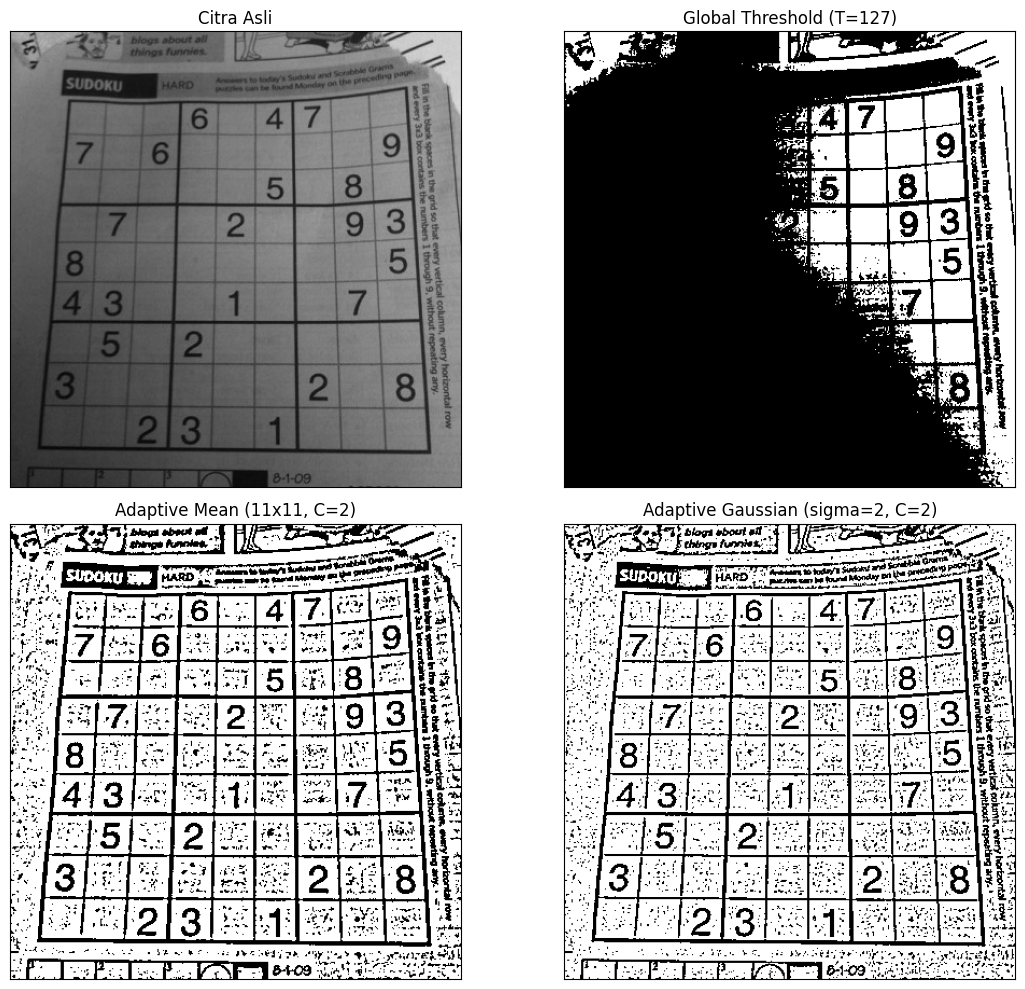

In [ ]:
### Adaptive Thresholding Manual

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# D1 No. 4 - Adaptive Threshold Manual
filename = '/content/drive/MyDrive/PCVK_img/sudoku-original.jpg'

img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(f'Gambar tidak ditemukan: {filename}')

# Parameter
T = 127
block_size = 11
C = 2
sigma = 2

# 1. Global Threshold manual
global_thresh = np.where(img > T, 255, 0).astype(np.uint8)

# Padding agar piksel di tepi juga dapat diproses
pad = block_size // 2
padded = np.pad(img.astype(np.float64), pad, mode='reflect')

# 2. Adaptive Mean Threshold manual
# Hitung jumlah piksel dalam setiap jendela menggunakan integral image
integral = np.pad(padded, ((1, 0), (1, 0)), mode='constant')
integral = integral.cumsum(axis=0).cumsum(axis=1)

local_sum = (
    integral[block_size:, block_size:]
    - integral[:-block_size, block_size:]
    - integral[block_size:, :-block_size]
    + integral[:-block_size, :-block_size]
)

local_mean = local_sum / (block_size * block_size)

adaptive_mean = np.where(
    img > (local_mean - C), 255, 0
).astype(np.uint8)

# 3. Buat kernel Gaussian secara manual
axis = np.arange(-pad, pad + 1, dtype=np.float64)
xx, yy = np.meshgrid(axis, axis)

gaussian_kernel = np.exp(
    -(xx**2 + yy**2) / (2 * sigma**2)
)
gaussian_kernel /= gaussian_kernel.sum()

# Hitung weighted mean Gaussian secara manual
gaussian_mean = np.zeros(img.shape, dtype=np.float64)

for i in range(block_size):
    for j in range(block_size):
        gaussian_mean += (
            padded[i:i + img.shape[0],
                   j:j + img.shape[1]]
            * gaussian_kernel[i, j]
        )

adaptive_gaussian = np.where(
    img > (gaussian_mean - C), 255, 0
).astype(np.uint8)

# 4. Tampilkan hasil
images = [
    img,
    global_thresh,
    adaptive_mean,
    adaptive_gaussian
]

titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    'Adaptive Mean (11x11, C=2)',
    'Adaptive Gaussian (sigma=2, C=2)'
]

plt.figure(figsize=(12, 10))

for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


Threshold global: 127
Threshold Otsu manual: 92
Intensitas minimum: 85
Intensitas maksimum: 108


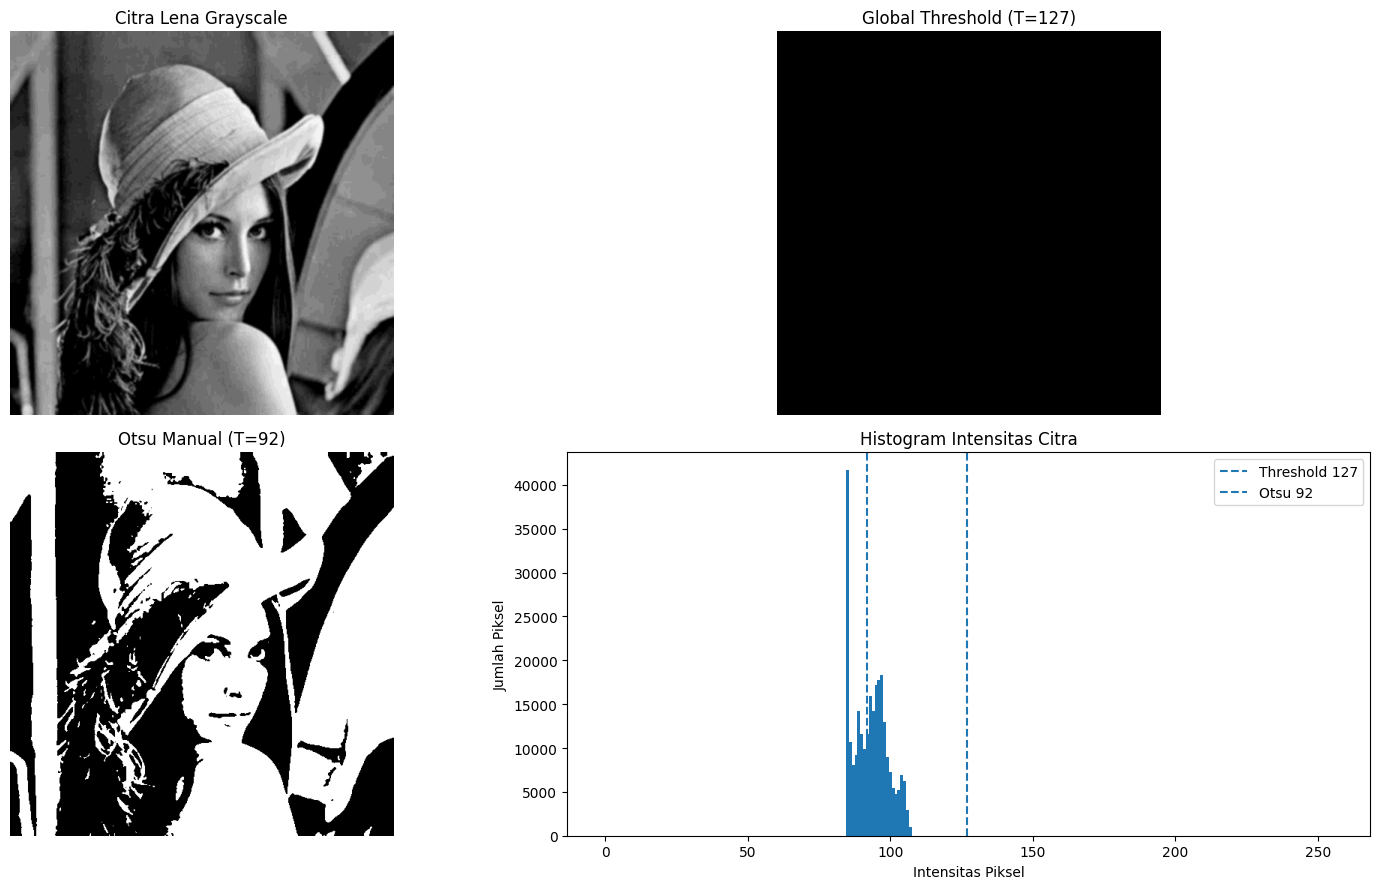

In [ ]:
### 5A Otsu manual pada gambar Lena


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
filename = '/content/drive/MyDrive/PCVK_img/lena_gs_lc2.jpg'

img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(f'Gambar tidak ditemukan: {filename}')

# Gaussian Blur sesuai contoh jobsheet
blur = cv.GaussianBlur(img, (5, 5), 0)

# Global Threshold manual
thresh = 127
global_binary = np.where(blur > thresh, 255, 0).astype(np.uint8)

# Fungsi Otsu manual
def otsu_manual(gray):
    histogram = np.bincount(gray.ravel(), minlength=256)
    total_pixels = gray.size
    intensities = np.arange(256)

    total_sum = np.dot(intensities, histogram)
    background_weight = 0
    background_sum = 0
    max_variance = -1
    best_threshold = 0

    for t in range(256):
        background_weight += histogram[t]
        background_sum += t * histogram[t]

        foreground_weight = total_pixels - background_weight

        if background_weight == 0 or foreground_weight == 0:
            continue

        mean_background = background_sum / background_weight
        mean_foreground = (
            total_sum - background_sum
        ) / foreground_weight

        variance = (
            background_weight * foreground_weight
            * (mean_background - mean_foreground) ** 2
        )

        if variance > max_variance:
            max_variance = variance
            best_threshold = t

    binary = np.where(
        gray > best_threshold, 255, 0
    ).astype(np.uint8)

    return binary, best_threshold, histogram

# Jalankan Otsu manual
otsu_binary, otsu_thresh, hist = otsu_manual(blur)

print('Threshold global:', thresh)
print('Threshold Otsu manual:', otsu_thresh)
print('Intensitas minimum:', int(blur.min()))
print('Intensitas maksimum:', int(blur.max()))

# Tampilkan citra dan histogram
plt.figure(figsize=(16, 9))

plt.subplot(2, 2, 1)
plt.imshow(blur, cmap='gray')
plt.title('Citra Lena Grayscale')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(global_binary, cmap='gray', vmin=0, vmax=255)
plt.title('Global Threshold (T=127)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(otsu_binary, cmap='gray', vmin=0, vmax=255)
plt.title(f'Otsu Manual (T={otsu_thresh})')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.bar(np.arange(256), hist, width=1)
plt.axvline(127, linestyle='--', label='Threshold 127')
plt.axvline(
    otsu_thresh, linestyle='--',
    label=f'Otsu {otsu_thresh}'
)
plt.title('Histogram Intensitas Citra')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Jumlah Piksel')
plt.legend()

plt.tight_layout()
plt.show()


Threshold global KTP: 127
Threshold Otsu KTP: 150


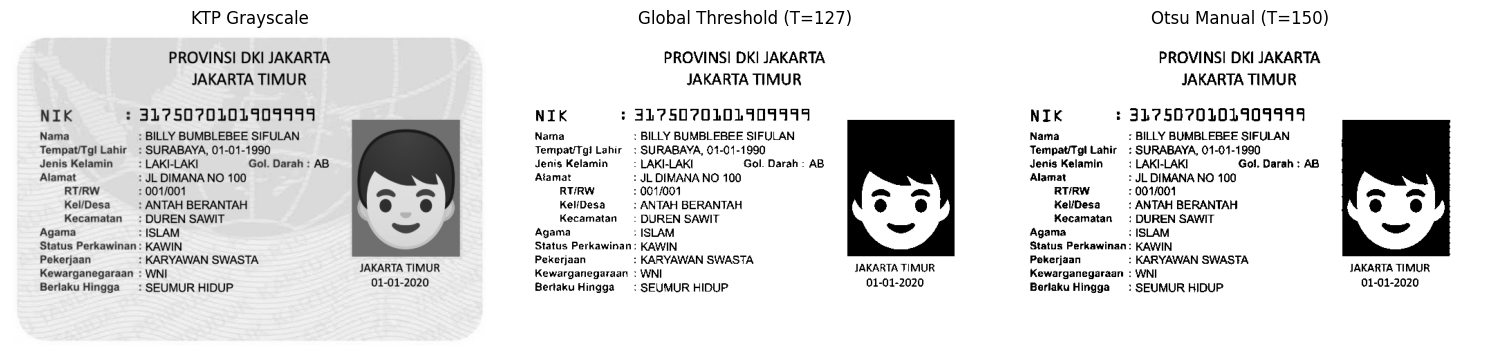

In [ ]:
### 5B Perbandingan dengan KTP

filename_ktp = '/content/drive/MyDrive/PCVK_img/ktp_fulan.jpg'

ktp = cv.imread(filename_ktp, cv.IMREAD_GRAYSCALE)

if ktp is None:
    raise FileNotFoundError(
        f'Gambar tidak ditemukan: {filename_ktp}'
    )

# Global threshold manual
ktp_global = np.where(ktp > 127, 255, 0).astype(np.uint8)

# Otsu manual menggunakan fungsi yang sama
ktp_otsu, ktp_threshold, ktp_hist = otsu_manual(ktp)

print('Threshold global KTP: 127')
print('Threshold Otsu KTP:', ktp_threshold)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(ktp, cmap='gray')
plt.title('KTP Grayscale')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(ktp_global, cmap='gray', vmin=0, vmax=255)
plt.title('Global Threshold (T=127)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(ktp_otsu, cmap='gray', vmin=0, vmax=255)
plt.title(f'Otsu Manual (T={ktp_threshold})')
plt.axis('off')

plt.tight_layout()
plt.show()


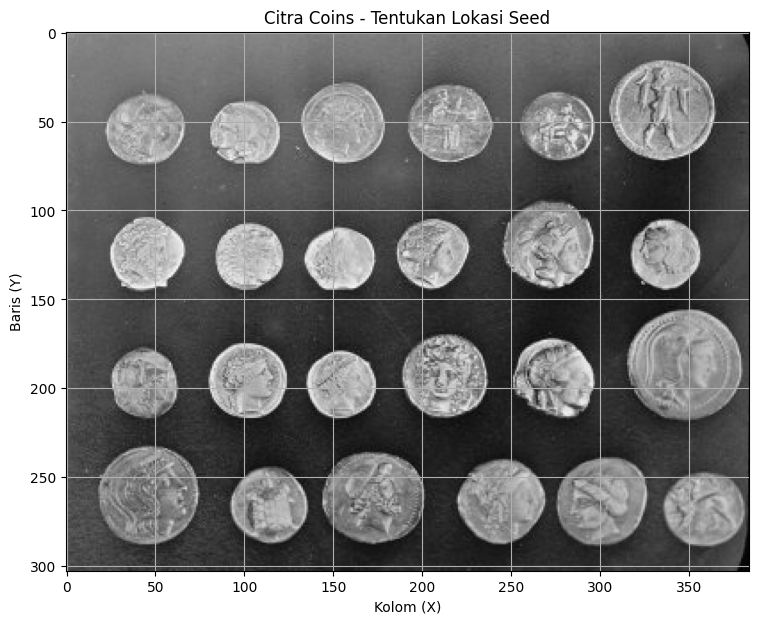

In [ ]:
### 6A Segmentasi Region dengan Tiga Seed


import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

img_coins = data.coins()

# Tampilkan citra untuk memeriksa lokasi seed
plt.figure(figsize=(10, 7))
plt.imshow(img_coins, cmap='gray')
plt.title('Citra Coins - Tentukan Lokasi Seed')
plt.xlabel('Kolom (X)')
plt.ylabel('Baris (Y)')
plt.grid()
plt.show()


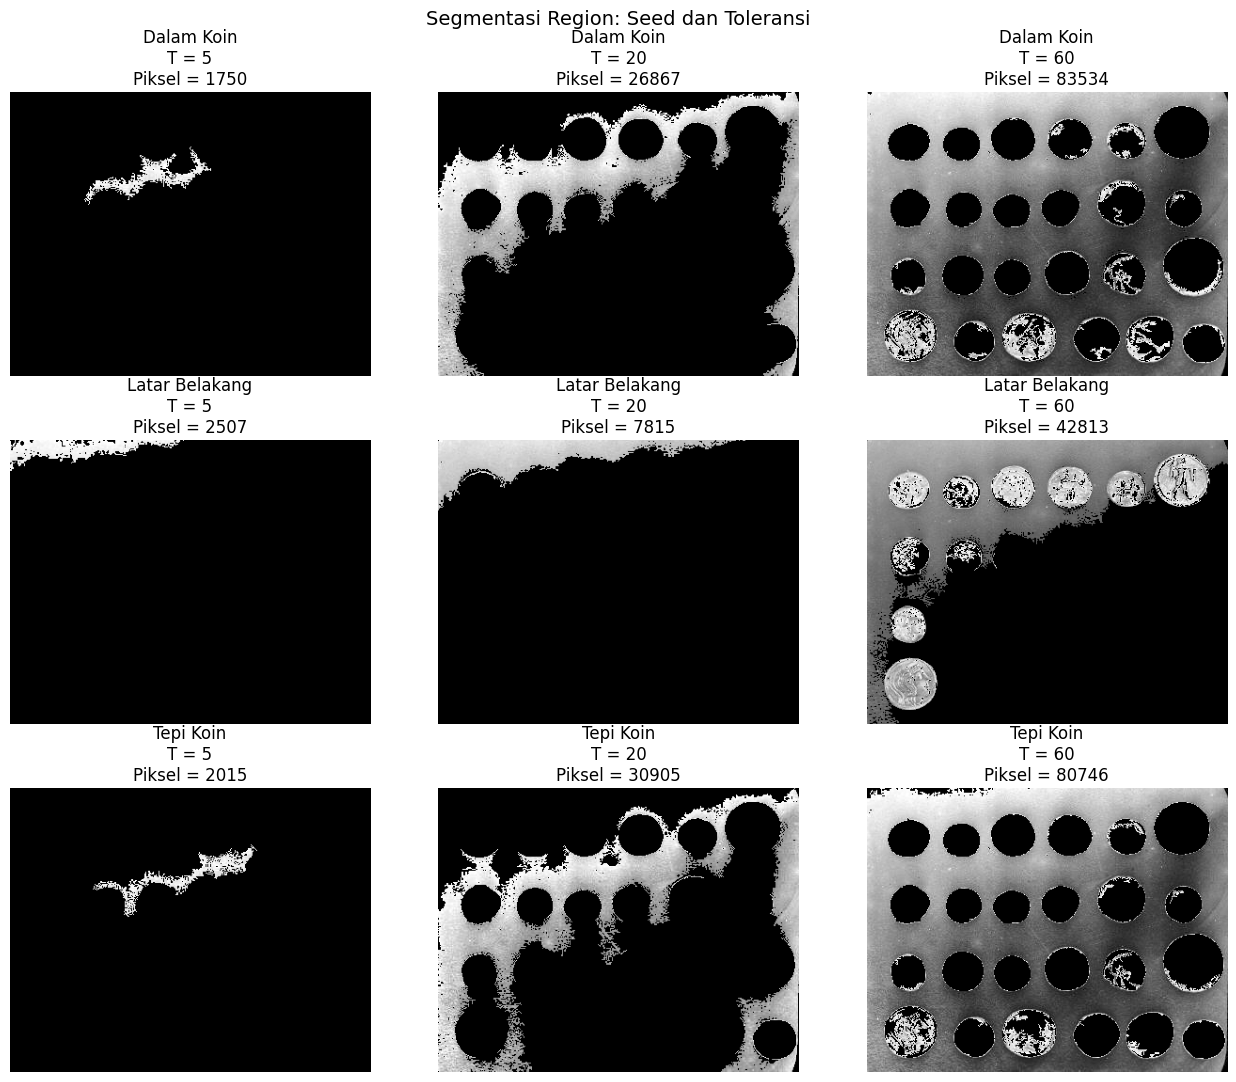

In [ ]:

seeds = {
    'Dalam Koin': (100, 100),
    'Latar Belakang': (10, 10),
    'Tepi Koin': (100, 145)
}

tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(13, 11))

for row, (seed_name, seed_point) in enumerate(seeds.items()):
    for col, tolerance in enumerate(tolerances):

        # Segmentasi berdasarkan seed dan toleransi
        mask = flood(
            img_coins,
            seed_point=seed_point,
            tolerance=tolerance
        )

        # Tampilkan region hasil segmentasi
        result = np.zeros_like(img_coins)
        result[mask] = img_coins[mask]

        axes[row, col].imshow(result, cmap='gray')
        axes[row, col].set_title(
            f'{seed_name}\nT = {tolerance}\n'
            f'Piksel = {np.sum(mask)}'
        )
        axes[row, col].axis('off')

plt.suptitle('Segmentasi Region: Seed dan Toleransi', fontsize=14)
plt.tight_layout()
plt.show()


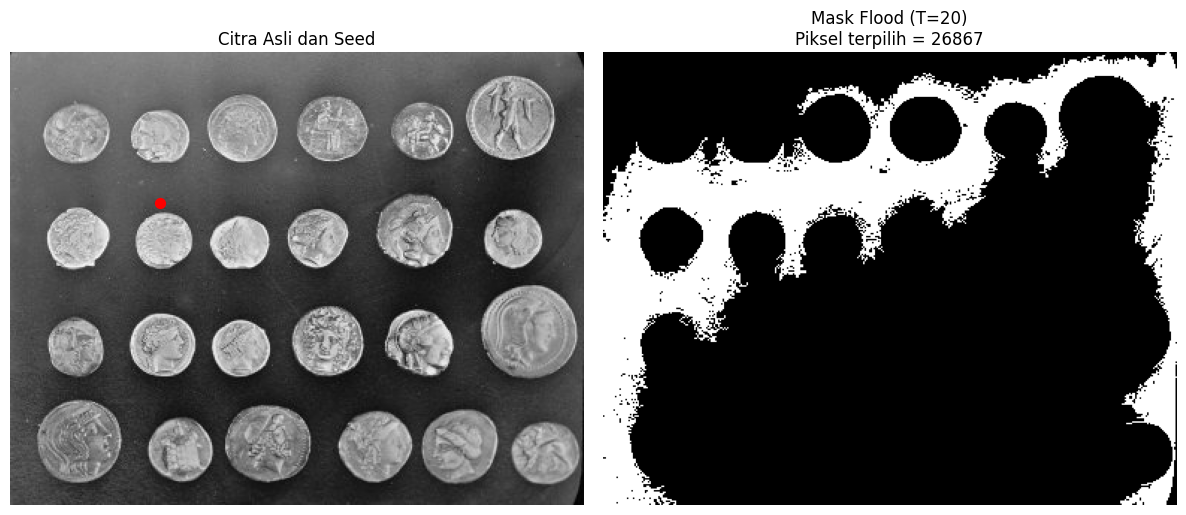

In [ ]:
### 6B - Mask Region dengan flood()

seed_point = seeds['Dalam Koin']
tolerance = 20

mask = flood(
    img_coins,
    seed_point=seed_point,
    tolerance=tolerance
)

# Visualisasi citra asli dan mask
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(img_coins, cmap='gray')
axes[0].scatter(
    seed_point[1], seed_point[0],
    color='red', s=50
)
axes[0].set_title('Citra Asli dan Seed')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title(
    f'Mask Flood (T={tolerance})\n'
    f'Piksel terpilih = {np.sum(mask)}'
)
axes[1].axis('off')

plt.tight_layout()
plt.show()


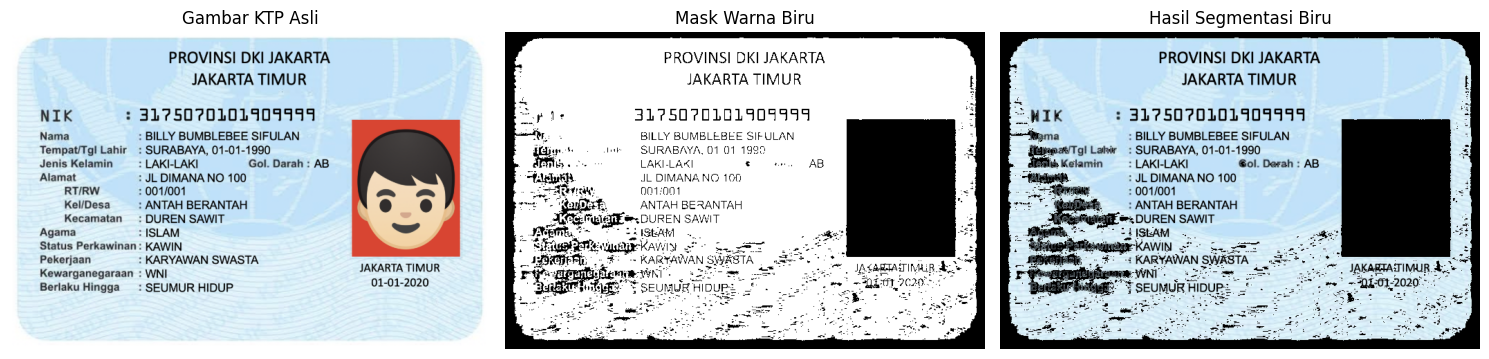

In [ ]:
### 7 - Segmentasi warna pada KTP

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Membaca gambar KTP
filename = '/content/drive/MyDrive/PCVK_img/ktp_fulan.jpg'
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan. Periksa nama dan lokasi file.")

# 2. Mengubah ruang warna BGR menjadi HSV
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
H, S, V = cv.split(hsv)

# 3. Menentukan piksel berwarna biru sesuai jobsheet
blue_y, blue_x = np.where(
    (H >= 85) & (H <= 130) &
    (S >= 25) & (V >= 40)
)

# 4. Membuat mask warna biru
mask = np.zeros(H.shape, dtype=np.uint8)
mask[blue_y, blue_x] = 255

# 5. Mengambil bagian biru dari gambar asli
result = cv.bitwise_and(img, img, mask=mask)

# 6. Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Gambar KTP Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title('Mask Warna Biru')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hasil Segmentasi Biru')
plt.axis('off')

plt.tight_layout()
plt.show()

## Tugas Kelompok

In [ ]:
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract opencv-python-headless pandas matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import cv2
import pytesseract
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from pytesseract import Output
from IPython.display import display

In [ ]:
### Upload 2 gambar yang berbeda
uploaded = files.upload()

image_paths = list(uploaded.keys())

if len(image_paths) != 2:
    raise ValueError("Upload tepat 2 gambar KTP dummy.")

print("Gambar yang diunggah:", image_paths)

Saving ktp_laksa_dummy.jpg to ktp_laksa_dummy (3).jpg
Saving ktp_dama_dummy.jpg to ktp_dama_dummy (3).jpg
Gambar yang diunggah: ['ktp_laksa_dummy (3).jpg', 'ktp_dama_dummy (3).jpg']


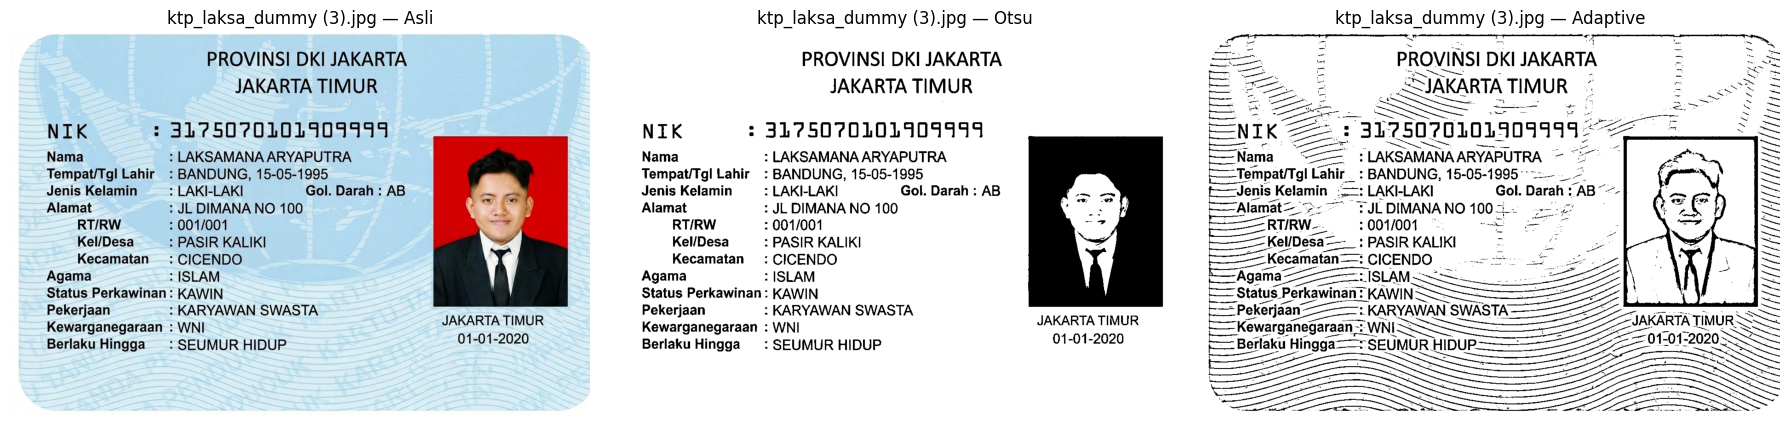

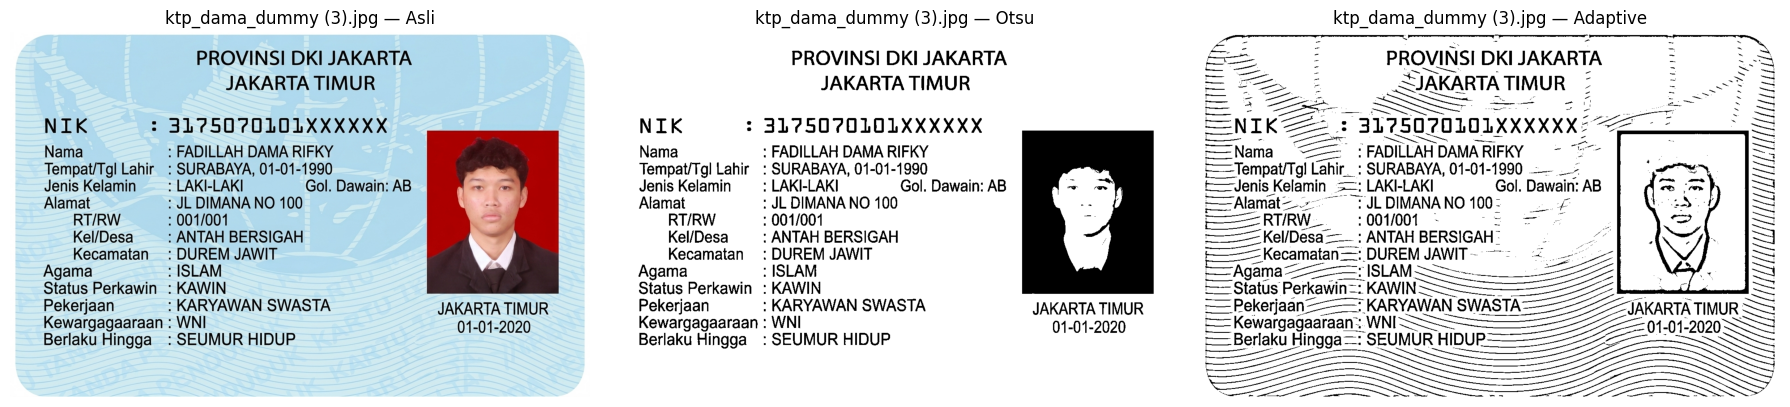

In [ ]:
### Buat 3 versi gambar
def preprocess_image(image_path):
    img = cv2.imread(image_path)

    if img is None:
        raise FileNotFoundError(f"Gambar tidak ditemukan: {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Otsu Thresholding
    otsu = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )[1]

    # Adaptive Gaussian Thresholding
    adaptive = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31, 10
    )

    return img, {
        "Asli": img,
        "Otsu": otsu,
        "Adaptive": adaptive
    }


images = {}

for path in image_paths:
    original, versions = preprocess_image(path)
    images[path] = {
        "original": original,
        "versions": versions
    }

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax, (method, image) in zip(
        axes, versions.items()
    ):
        if method == "Asli":
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray")

        ax.set_title(f"{path} — {method}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
### OCR kan setiap metode
ocr_results = {}

for path, data in images.items():
    ocr_results[path] = {}

    for method, image in data["versions"].items():
        text = pytesseract.image_to_string(
            image,
            lang="ind",
            config="--psm 6"
        )

        ocr_results[path][method] = text

        print("=" * 65)
        print(f"GAMBAR: {path} | METODE: {method}")
        print("=" * 65)
        print(text)

GAMBAR: ktp_laksa_dummy (3).jpg | METODE: Asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK : 3175070101909941
Nama : LAKSAMANA ARYAPUTRA
Tempat/Tgl Lahir : BANDUNG, 15-05-1995
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB —»
Alamat : JL DIMANA NO 100 Bag
RT/RW : 001/001 |
Kel/Desa : PASIR KALIKI
Kecamatan : CICENDO
Agama 2 ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SA SAPTA UMUR
Berlaku Hingga : SEUMUR HIDUP Se eta

GAMBAR: ktp_laksa_dummy (3).jpg | METODE: Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR
NIK : 3175070101409944
Nama : LAKSAMANA ARYAPUTRA
Tempat/Tgl Lahir : BANDUNG, 15-05-1995
Jenis Kelamin 1 LAKI-LAKI Gol. Darah : AB |
Alamat : JL DIMANA NO 100 H
RT/RW : 001/001
Kel/Desa : PASIR KALIKI ,
Kecamatan : CICENDO
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

GAMBAR: ktp_laksa_dummy (3).jpg | METODE: Adaptive
Ea, 5 S 1 ia sk - TI &
ST z PROVINSI DKI JAKAR


Hasil deteksi teks: ktp_laksa_dummy (3).jpg


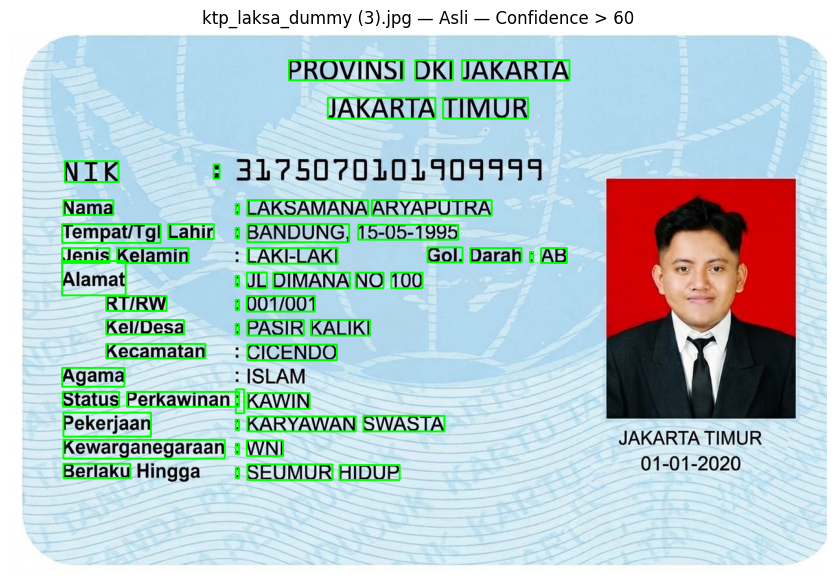

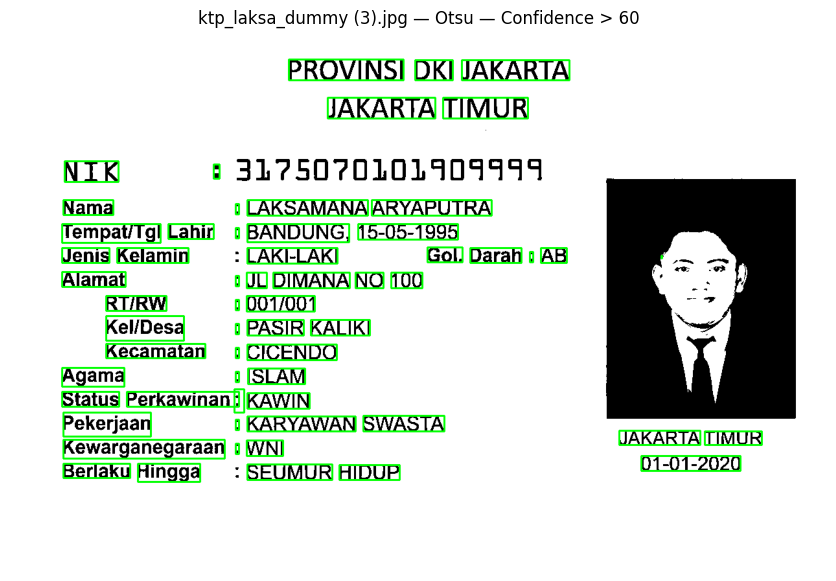

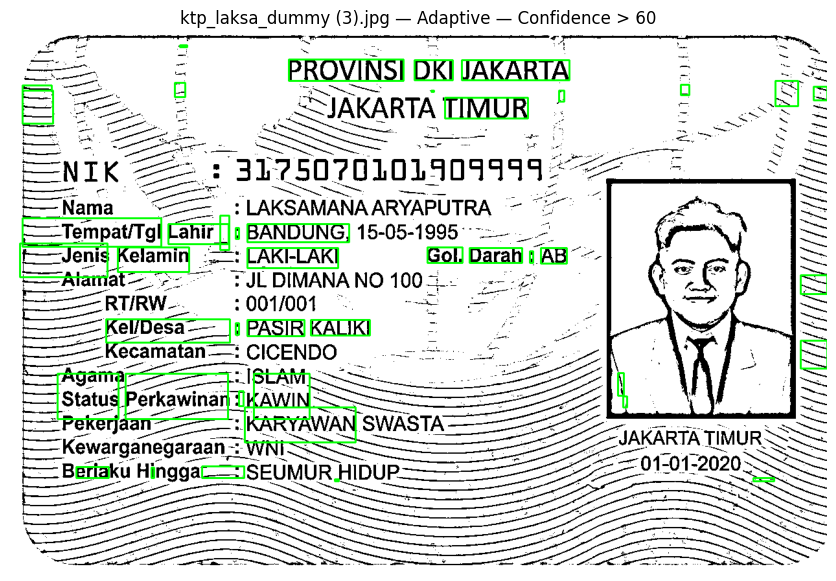


Hasil deteksi teks: ktp_dama_dummy (3).jpg


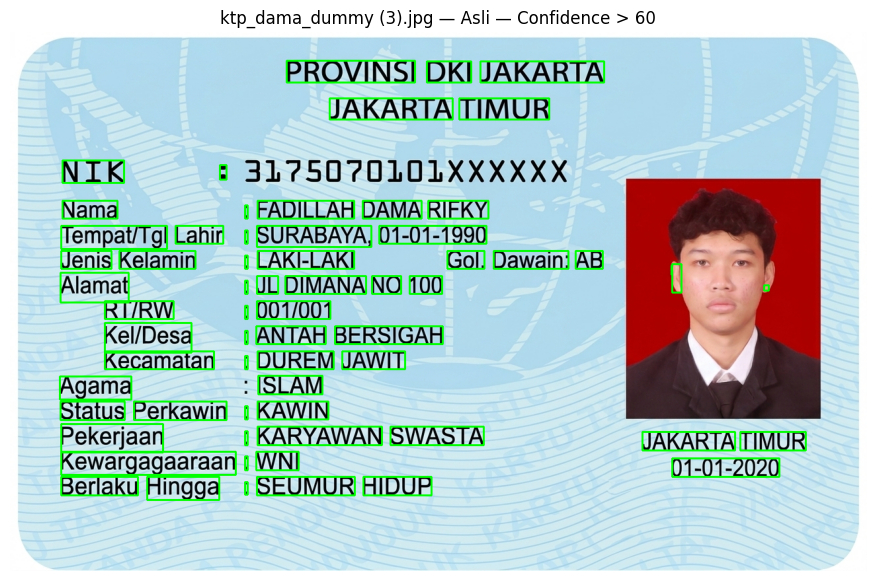

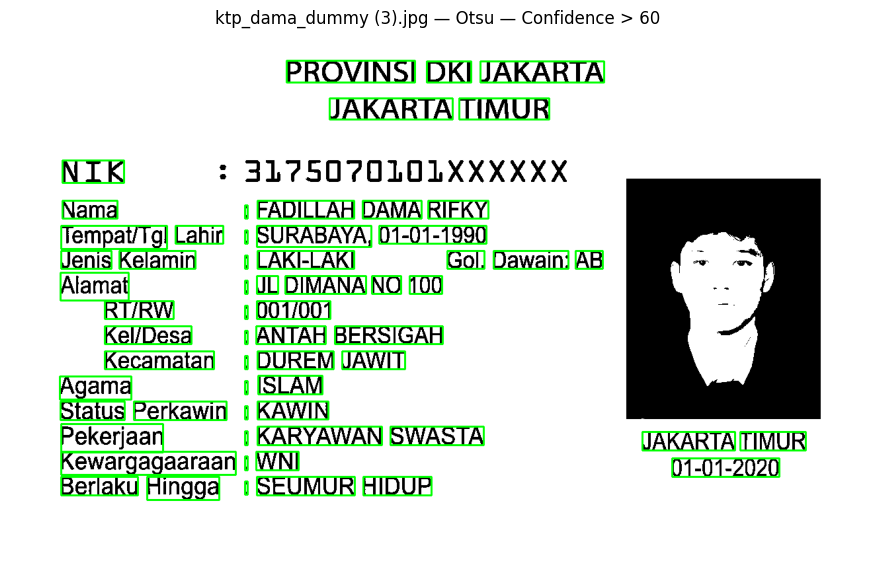

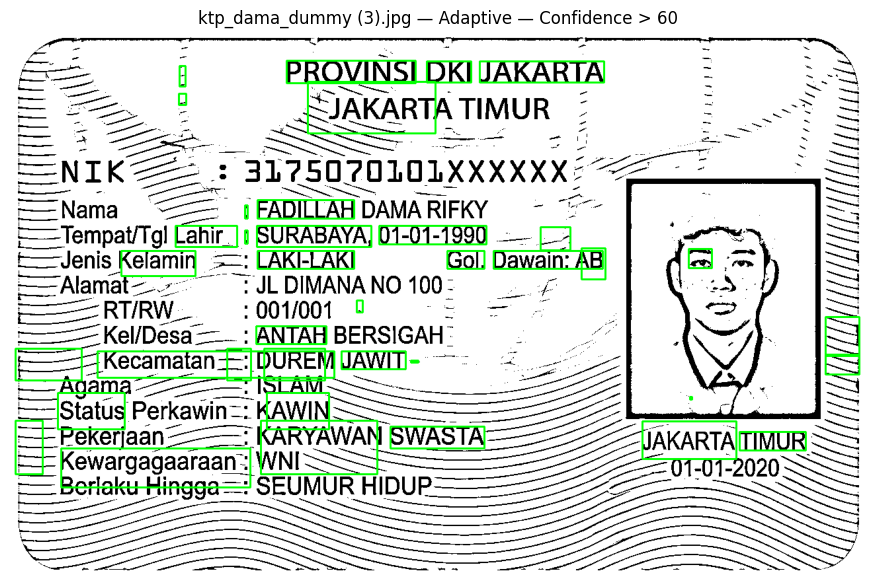

In [ ]:
### Tampilkan kotak hijau agar dikenali
for path, data in images.items():
    print(f"\nHasil deteksi teks: {path}")

    for method, image in data["versions"].items():
        if method == "Asli":
            display_img = image.copy()
        else:
            display_img = cv2.cvtColor(
                image, cv2.COLOR_GRAY2BGR
            )

        result = pytesseract.image_to_data(
            image,
            lang="ind",
            config="--psm 6",
            output_type=Output.DICT
        )

        for i, word in enumerate(result["text"]):
            word = word.strip()

            try:
                confidence = float(result["conf"][i])
            except (ValueError, TypeError):
                continue

            if word and confidence > 60:
                x = result["left"][i]
                y = result["top"][i]
                w = result["width"][i]
                h = result["height"][i]

                cv2.rectangle(
                    display_img,
                    (x, y), (x + w, y + h),
                    (0, 255, 0), 2
                )

        plt.figure(figsize=(14, 7))
        plt.imshow(
            cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB)
        )
        plt.title(f"{path} — {method} — Confidence > 60")
        plt.axis("off")
        plt.show()

In [ ]:
### Evaluasi Kecocokan
import re

def normalize(text):
    text = text.upper().strip()
    text = re.sub(r"\s+", " ", text)
    return text

# Isi dengan 10 kata/angka yang benar-benar terlihat
# pada masing-masing gambar dummy.
ground_truth = {
    image_paths[0]: [
        "PROVINSI DKI JAKARTA",
        "JAKARTA TIMUR",
        "LAKI-LAKI",
        "AB",
        "JL DIMANA NO 100",
        "001/001",
        "PASIR KALIKI",
        "ISLAM",
        "KARYAWAN SWASTA",
        "WNI"
    ],
    image_paths[1]: [
        "PROVINSI DKI JAKARTA",
        "JAKARTA TIMUR",
        "LAKI-LAKI",
        "AB",
        "JL DIMANA NO 100",
        "001/001",
        "ISLAM",
        "KAWIN",
        "KARYAWAN SWASTA",
        "WNI"
    ]
}

evaluation_rows = []

for path in image_paths:
    for item_no, reference in enumerate(ground_truth[path], start=1):
        row = {
            "Gambar": path,
            "No": item_no,
            "Teks Acuan": reference
        }

        for method in ["Asli", "Otsu", "Adaptive"]:
            extracted = normalize(ocr_results[path][method])
            target = normalize(reference)

            # Cocok jika teks acuan muncul utuh dalam hasil OCR
            row[f"OCR {method}"] = (
                "Cocok" if target in extracted else "Tidak cocok"
            )

        evaluation_rows.append(row)

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df)

,Gambar,No,Teks Acuan,OCR Asli,OCR Otsu,OCR Adaptive
0,ktp_laksa_dummy (3).jpg,1,PROVINSI DKI JAKARTA,Cocok,Cocok,Cocok
1,ktp_laksa_dummy (3).jpg,2,JAKARTA TIMUR,Cocok,Cocok,Cocok
2,ktp_laksa_dummy (3).jpg,3,LAKI-LAKI,Cocok,Cocok,Cocok
3,ktp_laksa_dummy (3).jpg,4,AB,Cocok,Cocok,Cocok
4,ktp_laksa_dummy (3).jpg,5,JL DIMANA NO 100,Cocok,Cocok,Tidak cocok
5,ktp_laksa_dummy (3).jpg,6,001/001,Cocok,Cocok,Tidak cocok
6,ktp_laksa_dummy (3).jpg,7,PASIR KALIKI,Cocok,Cocok,Cocok
7,ktp_laksa_dummy (3).jpg,8,ISLAM,Cocok,Cocok,Tidak cocok
8,ktp_laksa_dummy (3).jpg,9,KARYAWAN SWASTA,Cocok,Cocok,Tidak cocok
9,ktp_laksa_dummy (3).jpg,10,WNI,Cocok,Cocok,Tidak cocok


In [ ]:
### Hitung persentasi kecocokan
summary_rows = []

for path in image_paths:
    subset = evaluation_df[evaluation_df["Gambar"] == path]

    for method in ["Asli", "Otsu", "Adaptive"]:
        correct = (subset[f"OCR {method}"] == "Cocok").sum()
        total = len(subset)
        accuracy = (correct / total) * 100

        summary_rows.append({
            "Gambar": path,
            "Metode": method,
            "Item Cocok": f"{correct}/{total}",
            "Persentase Kecocokan (%)": round(accuracy, 2)
        })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Gambar,Metode,Item Cocok,Persentase Kecocokan (%)
0,ktp_laksa_dummy (3).jpg,Asli,10/10,100.0
1,ktp_laksa_dummy (3).jpg,Otsu,10/10,100.0
2,ktp_laksa_dummy (3).jpg,Adaptive,5/10,50.0
3,ktp_dama_dummy (3).jpg,Asli,10/10,100.0
4,ktp_dama_dummy (3).jpg,Otsu,10/10,100.0
5,ktp_dama_dummy (3).jpg,Adaptive,9/10,90.0


In [ ]:
confidence_rows = []

for path, data in images.items():
    for method, image in data["versions"].items():
        result = pytesseract.image_to_data(
            image,
            lang="ind",
            config="--psm 6",
            output_type=Output.DICT
        )

        confidences = []

        for word, conf in zip(result["text"], result["conf"]):
            word = word.strip()

            try:
                conf = float(conf)
            except (ValueError, TypeError):
                continue

            # Abaikan baris tanpa teks dan confidence negatif
            if word and conf >= 0:
                confidences.append(conf)

        average_confidence = (
            round(np.mean(confidences), 2)
            if confidences else 0
        )

        confidence_rows.append({
            "Gambar": path,
            "Metode": method,
            "Rata-rata Confidence": average_confidence
        })

confidence_df = pd.DataFrame(confidence_rows)
display(confidence_df)

,Gambar,Metode,Rata-rata Confidence
0,ktp_laksa_dummy (3).jpg,Asli,76.82
1,ktp_laksa_dummy (3).jpg,Otsu,86.03
2,ktp_laksa_dummy (3).jpg,Adaptive,43.18
3,ktp_dama_dummy (3).jpg,Asli,87.66
4,ktp_dama_dummy (3).jpg,Otsu,86.09
5,ktp_dama_dummy (3).jpg,Adaptive,44.86
